# Random Variables – Bernoulli and Binomial Simulation

**Name:** Aman Banka  **Registration No.:** 261100660030

This notebook solves:
* **Problem Set 1:** Simulating customer clicks using a Bernoulli random variable
* **Problem Set 2:** ML use case, the number of fraudulent transactions flagged (Binomial random variable)

A fixed random seed is used so that every output in this notebook can be reproduced exactly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

np.random.seed(123)          # reproducible results
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

---
# Problem Set 1: Simulating Customer Clicks Using a Bernoulli Random Variable

An organization sends promotional emails. Historical data show that a customer clicks the link with probability $p = 0.30$.

$$X = \begin{cases} 1, & \text{customer clicks} \\ 0, & \text{customer does not click} \end{cases} \qquad X \sim \text{Bernoulli}(0.30)$$

In [2]:
p = 0.30            # probability of a click (success)
q = 1 - p           # probability of no click (failure)
print("p = P(X = 1) =", p)
print("q = P(X = 0) =", round(q, 2))

p = P(X = 1) = 0.3
q = P(X = 0) = 0.7


## Step 1: Identify the random variable

1. **What does $X = 1$ represent?** The customer **clicks** the link in the promotional email (a "success").
2. **What does $X = 0$ represent?** The customer **does not click** the link (a "failure").
3. **What are the possible values of $X$?** Only two values: $X \in \{0, 1\}$.
4. **Discrete or continuous?** $X$ is a **discrete** random variable. It takes a finite, countable set of values (0 and 1), not a continuous range.
5. **Suitable distribution:** The **Bernoulli distribution** with parameter $p = 0.30$, i.e. $X \sim \text{Bernoulli}(0.30)$. It models a single trial with exactly two outcomes, success with probability $p$ and failure with probability $1-p$.

## Step 2: Theoretical PMF

For a Bernoulli($p$) random variable:

$$P(X = x) = p^{x}(1-p)^{1-x}, \qquad x \in \{0, 1\}$$

With $p = 0.30$:

| $x$ | $P(X = x)$ |
|---|---|
| 0 | $1 - p = 0.70$ |
| 1 | $p = 0.30$ |

The probabilities add to $0.70 + 0.30 = 1$.

In [3]:
x_values = np.array([0, 1])
theoretical_pmf = p**x_values * (1 - p)**(1 - x_values)     # p^x (1-p)^(1-x)

pmf_table = pd.DataFrame({"x": x_values, "P(X = x)": theoretical_pmf})
print(pmf_table.to_string(index=False))
print("Sum of probabilities =", theoretical_pmf.sum())

 x  P(X = x)
 0       0.7
 1       0.3
Sum of probabilities = 1.0


## Step 3: Generate outcomes for 20 customers

`np.random.binomial(n=1, ...)` generates Bernoulli observations, because a Binomial with a single trial ($n = 1$) is exactly a Bernoulli random variable.

In [4]:
sample_size = 20
samples = np.random.binomial(n=1, p=p, size=sample_size)

print("Generated outcomes:", samples)
print("Number of observations:", len(samples))

Generated outcomes: [0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0]
Number of observations: 20


**Answers**

1. **How many observations were generated?** **20** observations, one per customer.
2. **What does each zero represent?** A customer who **did not click** the email link.
3. **What does each one represent?** A customer who **clicked** the email link.
4. **Are the generated observations the same as the theoretical probabilities?** **No.** The observations are random 0/1 *outcomes*, not probabilities. Each one is a single random draw. Only the *proportion* of 1s and 0s in the sample estimates the probabilities 0.30 and 0.70, and with only 20 customers that proportion will usually differ somewhat from the theoretical values.

## Step 4: Count clicks and non-clicks

Completed code (the blanks are filled with **1** and **0**):

In [5]:
number_of_clicks = np.sum(samples == 1)
number_of_non_clicks = np.sum(samples == 0)

print("Number of clicks:", number_of_clicks)
print("Number of non-clicks:", number_of_non_clicks)
print("Total:", number_of_clicks + number_of_non_clicks)

Number of clicks: 4
Number of non-clicks: 16
Total: 20


**Answers**

* **How many customers clicked?** **4**
* **How many customers did not click?** **16**
* **Do the two counts add up to 20?** **Yes.** 4 + 16 = 20. Every customer either clicks or does not click, so the two outcomes are mutually exclusive and exhaustive.

## Step 5: Calculate the empirical PMF

The empirical (observed) probability of each outcome is its relative frequency in the sample:

$$\hat P(X = x) = \frac{\text{number of observations equal to } x}{\text{sample size}}$$

In [6]:
empirical_p0 = number_of_non_clicks / sample_size
empirical_p1 = number_of_clicks / sample_size
empirical_pmf = np.array([empirical_p0, empirical_p1])

print(f"Empirical P(X = 0) = {number_of_non_clicks}/{sample_size} = {empirical_p0:.2f}")
print(f"Empirical P(X = 1) = {number_of_clicks}/{sample_size} = {empirical_p1:.2f}")
print("Sum =", empirical_pmf.sum())

Empirical P(X = 0) = 16/20 = 0.80
Empirical P(X = 1) = 4/20 = 0.20
Sum = 1.0


## Step 6: Compare empirical and theoretical PMFs

In [7]:
comparison = pd.DataFrame({
    "x": x_values,
    "Theoretical P(X = x)": theoretical_pmf,
    "Empirical P(X = x)": empirical_pmf,
    "Absolute difference": np.abs(theoretical_pmf - empirical_pmf),
})
comparison_diff1 = abs(empirical_p1 - p)
comparison

,x,Theoretical P(X = x),Empirical P(X = x),Absolute difference
0,0,0.7,0.8,0.1
1,1,0.3,0.2,0.1


**Answers**

1. **Is the empirical probability of a click exactly 0.30?** **No.** It is **0.20** (4 clicks out of 20), which differs from 0.30 by 0.10.
2. **Which outcome has the larger probability?** **$X = 0$ (no click)**, both in theory (0.70 vs 0.30) and in the sample (0.80 vs 0.20).
3. **Why are the empirical and theoretical probabilities different?** The theoretical PMF describes the long-run behaviour of the process. The empirical PMF comes from a single, small random sample of only 20 customers, so it has **sampling variability**: by chance, a few more or fewer customers click than the expected $20 \times 0.30 = 6$. With only 20 observations, each customer shifts the proportion by 0.05. By the **Law of Large Numbers**, the empirical proportions get closer to the theoretical values as the sample size grows (see Step 13).

## Step 7: Plot the empirical and theoretical PMFs

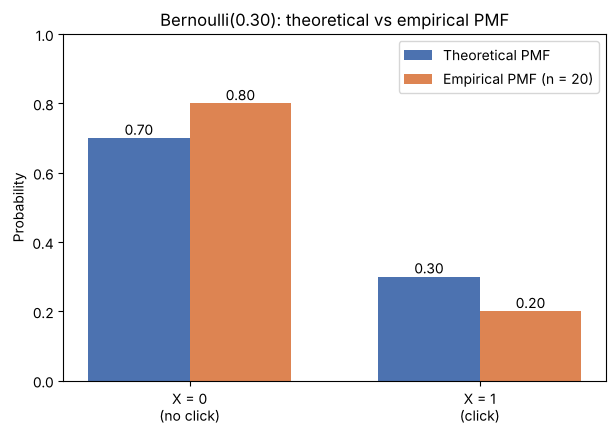

In [8]:
width = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar(x_values - width/2, theoretical_pmf, width, label="Theoretical PMF", color="#4C72B0")
b2 = ax.bar(x_values + width/2, empirical_pmf, width, label=f"Empirical PMF (n = {sample_size})", color="#DD8452")
ax.bar_label(b1, fmt="%.2f"); ax.bar_label(b2, fmt="%.2f")
ax.set_xticks(x_values, ["X = 0\n(no click)", "X = 1\n(click)"])
ax.set_ylabel("Probability")
ax.set_ylim(0, 1)
ax.set_title("Bernoulli(0.30): theoretical vs empirical PMF")
ax.legend()
plt.show()

## Step 8: Theoretical expectation

$$E[X] = \sum_x x\,P(X=x) = 0\cdot(1-p) + 1\cdot p = p = 0.30$$

In [9]:
theoretical_mean = np.sum(x_values * theoretical_pmf)
print("Theoretical expectation E[X] =", round(theoretical_mean, 4))

Theoretical expectation E[X] = 0.3


## Step 9: Empirical expectation

The empirical expectation is the sample mean $\bar x = \frac{1}{N}\sum_{i=1}^{N} x_i$. For 0/1 data this equals the proportion of clicks.

In [10]:
empirical_mean = np.mean(samples)
print("Empirical expectation (sample mean) =", round(empirical_mean, 4))

Empirical expectation (sample mean) = 0.2


## Step 10: Theoretical variance

$$\operatorname{Var}(X) = E[X^2] - (E[X])^2 = p - p^2 = p(1-p) = 0.30 \times 0.70 = 0.21$$

(For a Bernoulli variable $X^2 = X$, so $E[X^2] = p$.)

In [11]:
theoretical_var = np.sum((x_values - theoretical_mean)**2 * theoretical_pmf)
print("Theoretical variance Var(X) = p(1-p) =", round(theoretical_var, 4))

Theoretical variance Var(X) = p(1-p) = 0.21


## Step 11: Empirical variance

The empirical variance is $\frac{1}{N}\sum (x_i - \bar x)^2$ (`np.var`, `ddof=0`). This matches the PMF-based definition used in Step 10, and for 0/1 data it equals $\hat p(1-\hat p)$. The unbiased sample variance (`ddof=1`, divisor $N-1$) is also shown for reference.

In [12]:
empirical_var = np.var(samples)              # ddof = 0
print("Empirical variance (ddof=0)          =", round(empirical_var, 4))
print("Check: p_hat * (1 - p_hat)           =", round(empirical_p1 * (1 - empirical_p1), 4))
print("Sample variance (ddof=1, unbiased)   =", round(np.var(samples, ddof=1), 4))

Empirical variance (ddof=0)          = 0.16
Check: p_hat * (1 - p_hat)           = 0.16
Sample variance (ddof=1, unbiased)   = 0.1684


## Step 12: Final result table

In [13]:
final_table = pd.DataFrame({
    "Measure": ["P(X = 0)", "P(X = 1)", "Expectation", "Variance"],
    "Theoretical value": [theoretical_pmf[0], theoretical_pmf[1], theoretical_mean, theoretical_var],
    "Empirical value":   [empirical_p0, empirical_p1, empirical_mean, empirical_var],
})
final_table["Absolute difference"] = (final_table["Theoretical value"] - final_table["Empirical value"]).abs()
final_table = final_table.round(4)
d0, d1, dm, dv = final_table["Absolute difference"]
final_table

,Measure,Theoretical value,Empirical value,Absolute difference
0,P(X = 0),0.70,0.80,0.10
1,P(X = 1),0.30,0.20,0.10
2,Expectation,0.30,0.20,0.10
3,Variance,0.21,0.16,0.05


| Measure | Theoretical value | Empirical value | Absolute difference |
|---|---|---|---|
| $P(X=0)$ | 0.70 | 0.8000 | 0.1000 |
| $P(X=1)$ | 0.30 | 0.2000 | 0.1000 |
| Expectation | 0.30 | 0.2000 | 0.1000 |
| Variance | 0.21 | 0.1600 | 0.0500 |

## Step 13: Effect of sample size

The experiment is repeated with $N = 10, 100, 1\,000, 10\,000$ customers.

In [14]:
sample_sizes = [10, 100, 1_000, 10_000]
rows, res = [], {}
for N in sample_sizes:
    s = np.random.binomial(n=1, p=p, size=N)
    r = {"Sample size": N,
         "Empirical P(X = 0)": np.mean(s == 0),
         "Empirical P(X = 1)": np.mean(s == 1),
         "Empirical mean": np.mean(s),
         "Empirical variance": np.var(s)}
    rows.append(r)
    res[N] = r

size_table = pd.DataFrame(rows)
size_table["|P(X=1) - 0.30|"] = (size_table["Empirical P(X = 1)"] - p).abs()
size_table = size_table.round(4)
res100diff = abs(res[100]["Empirical P(X = 1)"] - p)
print("Theoretical values: P(X=0) = 0.70, P(X=1) = 0.30, mean = 0.30, variance = 0.21\n")
size_table

Theoretical values: P(X=0) = 0.70, P(X=1) = 0.30, mean = 0.30, variance = 0.21



,Sample size,Empirical P(X = 0),Empirical P(X = 1),Empirical mean,Empirical variance,|P(X=1) - 0.30|
0,10,0.7000,0.3000,0.3000,0.2100,0.0000
1,100,0.7700,0.2300,0.2300,0.1771,0.0700
2,1000,0.7150,0.2850,0.2850,0.2038,0.0150
3,10000,0.6997,0.3003,0.3003,0.2101,0.0003


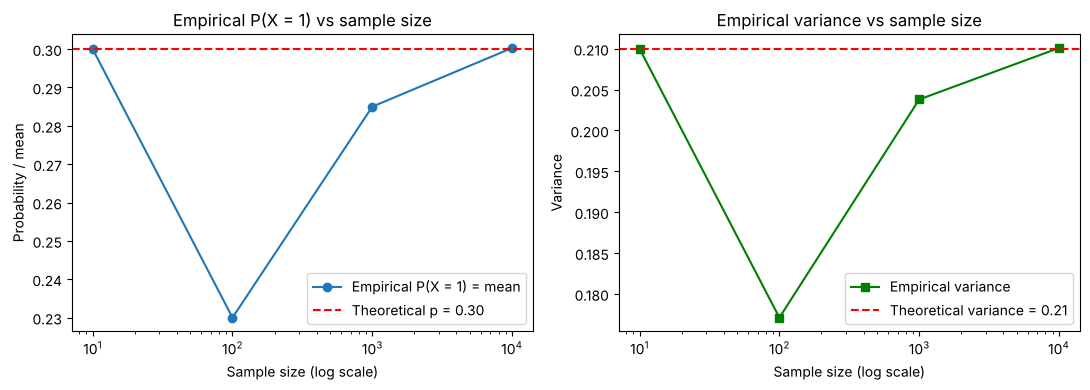

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sample_sizes, size_table["Empirical P(X = 1)"], "o-", label="Empirical P(X = 1) = mean")
axes[0].axhline(p, color="red", ls="--", label="Theoretical p = 0.30")
axes[0].set_xscale("log"); axes[0].set_xlabel("Sample size (log scale)")
axes[0].set_ylabel("Probability / mean"); axes[0].set_title("Empirical P(X = 1) vs sample size")
axes[0].legend()

axes[1].plot(sample_sizes, size_table["Empirical variance"], "s-", color="green", label="Empirical variance")
axes[1].axhline(p*(1-p), color="red", ls="--", label="Theoretical variance = 0.21")
axes[1].set_xscale("log"); axes[1].set_xlabel("Sample size (log scale)")
axes[1].set_ylabel("Variance"); axes[1].set_title("Empirical variance vs sample size")
axes[1].legend()
plt.tight_layout()
plt.show()

| Sample size | Empirical $P(X=0)$ | Empirical $P(X=1)$ | Empirical mean | Empirical variance |
|---|---|---|---|---|
| 10 | 0.7000 | 0.3000 | 0.3000 | 0.2100 |
| 100 | 0.7700 | 0.2300 | 0.2300 | 0.1771 |
| 1,000 | 0.7150 | 0.2850 | 0.2850 | 0.2038 |
| 10,000 | 0.6997 | 0.3003 | 0.3003 | 0.2101 |

**Observation:** Small samples fluctuate a lot. At $N = 10$ the click proportion can only be a multiple of 0.10 (each customer changes it by 0.10). This run happened to land on 0.30, but that is luck, not precision, and a repeat could easily give 0.10 or 0.50. At $N = 100$ the proportion is 0.23, off by 0.07. As $N$ grows to 1,000 and 10,000, the empirical $P(X=0)$, $P(X=1)$, mean and variance settle close to 0.70, 0.30, 0.30 and 0.21. At $N = 10\,000$ the click proportion is 0.3003, within about 0.001 of 0.30. This is the **Law of Large Numbers**. The typical error of the estimated proportion is the standard error $\sqrt{p(1-p)/N}$, which shrinks like $1/\sqrt{N}$: ≈ 0.145 at $N=10$, 0.046 at $N=100$, 0.014 at $N=1000$ and 0.0046 at $N=10\,000$.

---
# Problem Set 2: ML Use Case, Number of Fraudulent Transactions Flagged

A fraud-detection model examines **50 transactions every hour**. Each transaction has a **4 %** probability of being flagged as potentially fraudulent, and flagging decisions are assumed to be independent.

$$X = \text{number of transactions flagged in one hour}, \qquad X \sim \text{Binomial}(n = 50,\ p = 0.04)$$

The fraud investigation team can examine **at most four** flagged transactions per hour.

## Task 1: Simulate 20,000 independent one-hour periods

In every simulated hour, exactly 50 transactions are examined, each with flagging probability 0.04, and $X$ records the total number flagged. `np.random.binomial(n=50, p=0.04, size=20000)` produces one Binomial count per hour, i.e. 20,000 hours at once.

In [16]:
n_tx = 50            # transactions examined per hour
p_flag = 0.04        # probability that a transaction is flagged
n_hours = 20_000     # number of simulated one-hour periods
capacity = 4         # max flagged transactions the team can examine per hour

X = np.random.binomial(n=n_tx, p=p_flag, size=n_hours)

print("Shape of X:", X.shape)
print("First 20 simulated hours:", X[:20])
print("Minimum flagged in an hour:", X.min())
print("Maximum flagged in an hour:", X.max())

Shape of X: (20000,)
First 20 simulated hours: [2 0 1 2 2 1 2 7 3 0 2 2 3 0 1 0 3 0 6 3]
Minimum flagged in an hour: 0
Maximum flagged in an hour: 8


### Distribution of the simulated counts (empirical vs theoretical PMF)

Theoretical PMF: $P(X = k) = \binom{50}{k}(0.04)^k(0.96)^{50-k}$.

In [17]:
k = np.arange(0, X.max() + 1)
empirical_pmf_X = np.array([np.mean(X == v) for v in k])
theoretical_pmf_X = np.array([comb(n_tx, v) * p_flag**v * (1 - p_flag)**(n_tx - v) for v in k])

pmf_X = pd.DataFrame({
    "k (flagged)": k,
    "Hours observed": [int(np.sum(X == v)) for v in k],
    "Empirical P(X = k)": empirical_pmf_X,
    "Theoretical P(X = k)": theoretical_pmf_X,
    "Absolute difference": np.abs(empirical_pmf_X - theoretical_pmf_X),
}).round(4)
pmf_X

,k (flagged),Hours observed,Empirical P(X = k),Theoretical P(X = k),Absolute difference
0,0,2516,0.1258,0.1299,0.0041
1,1,5464,0.2732,0.2706,0.0026
2,2,5521,0.2760,0.2762,0.0002
3,3,3728,0.1864,0.1842,0.0022
4,4,1832,0.0916,0.0902,0.0014
5,5,668,0.0334,0.0346,0.0012
6,6,203,0.0102,0.0108,0.0007
7,7,53,0.0026,0.0028,0.0002
8,8,15,0.0008,0.0006,0.0001


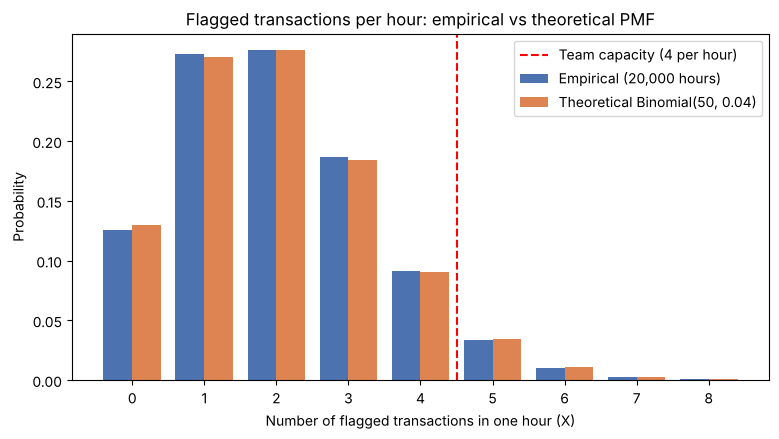

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(k - 0.2, empirical_pmf_X, 0.4, label="Empirical (20,000 hours)", color="#4C72B0")
ax.bar(k + 0.2, theoretical_pmf_X, 0.4, label="Theoretical Binomial(50, 0.04)", color="#DD8452")
ax.axvline(capacity + 0.5, color="red", ls="--", label="Team capacity (4 per hour)")
ax.set_xticks(k)
ax.set_xlabel("Number of flagged transactions in one hour (X)")
ax.set_ylabel("Probability")
ax.set_title("Flagged transactions per hour: empirical vs theoretical PMF")
ax.legend()
plt.show()

### Mean and variance

Theoretical: $E[X] = np = 50 \times 0.04 = 2$, $\operatorname{Var}(X) = np(1-p) = 50 \times 0.04 \times 0.96 = 1.92$.

In [19]:
theo_mean_X = n_tx * p_flag
theo_var_X = n_tx * p_flag * (1 - p_flag)
emp_mean_X = X.mean()
emp_var_X = X.var()

summary_X = pd.DataFrame({
    "Measure": ["Expectation E[X]", "Variance Var(X)"],
    "Theoretical": [theo_mean_X, theo_var_X],
    "Empirical (simulation)": [emp_mean_X, emp_var_X],
})
summary_X["Absolute difference"] = (summary_X["Theoretical"] - summary_X["Empirical (simulation)"]).abs()
summary_X.round(4)

,Measure,Theoretical,Empirical (simulation),Absolute difference
0,Expectation E[X],2.00,2.0034,0.0034
1,Variance Var(X),1.92,1.8854,0.0346


### Capacity check: how often is the team overloaded?

The team can handle at most 4 flagged transactions per hour, so an hour is **overloaded** when $X > 4$:

$$P(X > 4) = 1 - P(X \le 4) = 1 - \sum_{k=0}^{4}\binom{50}{k}(0.04)^k(0.96)^{50-k}$$

In [20]:
p_le4_theory = sum(comb(n_tx, v) * p_flag**v * (1 - p_flag)**(n_tx - v) for v in range(capacity + 1))
p_over_theory = 1 - p_le4_theory
p_over_emp = np.mean(X > capacity)
overloaded_hours = int(np.sum(X > capacity))

excess = np.maximum(X - capacity, 0)          # flagged transactions the team cannot examine
print(f"Theoretical P(X <= 4)          = {p_le4_theory:.4f}")
print(f"Theoretical P(X > 4)           = {p_over_theory:.4f}")
print(f"Empirical   P(X > 4)           = {p_over_emp:.4f}  ({overloaded_hours} of {n_hours} hours)")
print(f"Expected overloaded hours      = {n_hours * p_over_theory:.0f} of {n_hours}")
print(f"Average unexamined per hour    = {excess.mean():.4f}")
print(f"Total unexamined transactions  = {excess.sum()} over {n_hours} hours")

X_max, excess_mean = X.max(), excess.mean()
p_over_emp_pct, p_over_theory_pct = 100 * p_over_emp, 100 * p_over_theory

Theoretical P(X <= 4)          = 0.9510
Theoretical P(X > 4)           = 0.0490
Empirical   P(X > 4)           = 0.0469  (939 of 20000 hours)
Expected overloaded hours      = 979 of 20000
Average unexamined per hour    = 0.0646
Total unexamined transactions  = 1293 over 20000 hours


### Conclusions

* The 20,000 simulated hours give an average of **2.0034** flagged transactions per hour (theory: 2) and a variance of **1.8854** (theory: 1.92). The empirical PMF closely matches the Binomial(50, 0.04) PMF, because 20,000 repetitions is a large sample (Law of Large Numbers).
* Most hours have between 0 and 4 flags. The most likely values are 1 and 2 flags per hour, and the largest count observed in any hour was 8.
* The team's capacity of 4 is **exceeded in about 4.70 % of hours** (simulation: 939 of 20,000 hours; theory: 4.90 %), roughly one hour in twenty. In those hours, some flagged transactions cannot be examined within the hour (on average 0.0646 per hour overall).
* This result relies on the stated assumption that flagging decisions are **independent**. If fraud attempts arrive in bursts (correlated transactions), large values of $X$ would be more likely than the Binomial model predicts, and the overload probability would be higher.